# Track 3 AI Detector: authenticity score for Sentinel-2 tiles

For every 256x256x13 Sentinel-2 tile, one function `authenticity(tile)` returns:

| output | meaning |
|---|---|
| `trust_score` | 0 to 100, high = looks like a real sensor image |
| `channel_flags` | which sanity checks / bands look wrong |
| `heatmap` | 256x256 map of where the tile looks edited |

**Design rules**
1. **Clean-only core.** We never train on attacks. We learn what *clean* tiles look like; anything far from that is suspicious.
2. **Split by scene, not by tile.** Neighbouring tiles share almost the same pixels, a random split leaks and inflates results.
3. **Real attacks only.** Evaluation uses the teammates' real `pair_xxx_original / attacked / masks / manifest` files. No self-made attacks.
4. **Plain functions, plain arrays.** No custom classes, one idea per cell.

**Pipeline:** `data -> split by scene -> sanity checks -> cross-band models -> features -> clean statistics + threshold -> authenticity() -> evaluation on real pairs -> diagnostics -> export`

> Kaggle setup: turn **Internet ON** (needed for the TUM download; the archive is streamed, no 33 GB download).

## 1. Config and paths
Everything you may want to change lives in this one cell.

In [1]:
import os, re, io, glob, json, time, hashlib, tarfile, subprocess, warnings, pickle, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

def _ensure(pkg, mod=None):
    try:
        __import__(mod or pkg)
    except ImportError:
        subprocess.run(f"pip -q install {pkg}", shell=True, check=True)
_ensure("rasterio"); _ensure("cryptography")
import rasterio

# ---------- paths ----------
TUM_URL   = "https://dataserv.ub.tum.de/s/m1554803/download?path=%2F&files=ROIs1158_spring_s2.tar.gz"
DATA_DIR  = "/kaggle/temp/tum_data"
ARCHIVE   = f"{DATA_DIR}/ROIs1158_spring_s2.tar.gz"      # used if it already exists, otherwise streamed
TILE_DIR  = f"{DATA_DIR}/tiles"                          # the subset we keep
OUT_DIR   = "/kaggle/working/outputs"
PAIRS_DIR = "/kaggle/input/datasets/onsgui/track3-pairs"  # teammates' pair_xxx_* files
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

# ---------- clean data subset ----------
N_TILES        = 800    # total tiles to keep
MAX_PER_SCENE  = 10     # cap per scene -> ~80 scenes (many scenes = a stable threshold)
TILE_STRIDE    = 4      # keep every 4th patch inside a scene (less redundancy between neighbours)
MIN_SCENES     = 10

# ---------- split (by scene) ----------
SPLIT_FRACS = {"train": 0.4, "calib": 0.3, "test": 0.3}
# train = fit the cross-band regressors | calib = clean statistics + threshold | test = honest false-positive rate

# ---------- sensor / model constants ----------
BAND_NAMES   = ["B1","B2","B3","B4","B5","B6","B7","B8","B8A","B9","B10","B11","B12"]
TARGET_BANDS = ["B4","B5","B8","B11"]           # bands we predict from the others
PATCH, PATCH_STRIDE = 64, 32                    # patch grid -> 7 x 7 patches per tile
FPR_TARGET   = 0.01                             # 1 % false positives on clean data
SEED = 42
B = {n: i for i, n in enumerate(BAND_NAMES)}    # band name -> index
print("config ok | rasterio", rasterio.__version__)

config ok | rasterio 1.5.1


## 2. Get the clean data (SEN12MS-CR, Sentinel-2 only)

Source: TUM server, `ROIs1158_spring_s2.tar.gz`. Tiles are named `ROIs1158_spring/s2_<scene>/ROIs1158_spring_s2_<scene>_p<patch>.tif`, so **ROI + scene id** is our "region".

`get_tiles()` reads the local archive if it exists, otherwise **streams** it over HTTP and stops after `N_TILES` (no 33 GB download). It keeps at most `MAX_PER_SCENE` tiles per scene (every `TILE_STRIDE`-th one). The kept tiles are tagged with the config that produced them, so changing `N_TILES / MAX_PER_SCENE / TILE_STRIDE` re-extracts automatically.

In [2]:
TILE_RE = re.compile(r"(ROIs\d+_[a-z]+)_s2_(\d+)_p(\d+)\.tif$")

def parse_tile_name(name):
    """'.../ROIs1158_spring_s2_17_p203.tif' -> dict(roi, scene, patch); None if not a tile."""
    m = TILE_RE.search(name)
    if m is None:
        return None
    return dict(roi=m.group(1), scene=int(m.group(2)), patch=int(m.group(3)))

def extract_subset(tar):
    """Walk through the tar members once, keep a capped, strided subset of tiles."""
    seen, taken, total = {}, {}, 0
    for member in tar:
        if not member.isfile():
            continue
        info = parse_tile_name(member.name)
        if info is None:
            continue
        key = (info["roi"], info["scene"])
        seen[key] = seen.get(key, 0) + 1
        if taken.get(key, 0) >= MAX_PER_SCENE or seen[key] % TILE_STRIDE != 0:
            continue
        data = tar.extractfile(member).read()
        with open(os.path.join(TILE_DIR, os.path.basename(member.name)), "wb") as f:
            f.write(data)
        taken[key] = taken.get(key, 0) + 1
        total += 1
        if total >= N_TILES:
            break
    return taken

def get_tiles():
    sig = dict(N_TILES=N_TILES, MAX_PER_SCENE=MAX_PER_SCENE, TILE_STRIDE=TILE_STRIDE)
    sig_file = os.path.join(TILE_DIR, "_config.json")
    n_have = len(glob.glob(f"{TILE_DIR}/*.tif"))
    old = json.load(open(sig_file)) if os.path.exists(sig_file) else None
    if n_have >= N_TILES and old == sig:
        print(f"already have {n_have} tiles for this config, skipping download"); return
    shutil.rmtree(TILE_DIR, ignore_errors=True)          # tiles from another config would be stale
    os.makedirs(TILE_DIR)
    if os.path.exists(ARCHIVE):
        print("reading the local archive"); t0 = time.time()
        with tarfile.open(ARCHIVE, "r|gz") as tar:
            taken = extract_subset(tar)
    else:
        print("streaming the archive from TUM (stops after N_TILES)"); t0 = time.time()
        import requests
        r = requests.get(TUM_URL, stream=True, timeout=120)
        r.raise_for_status()
        with tarfile.open(fileobj=r.raw, mode="r|gz") as tar:
            taken = extract_subset(tar)
        r.close()
    json.dump(sig, open(sig_file, "w"))
    print(f"kept {sum(taken.values())} tiles from {len(taken)} scenes in {time.time()-t0:.0f}s")

get_tiles()

streaming the archive from TUM (stops after N_TILES)
kept 410 tiles from 41 scenes in 2056s


## 3. Region split and hash exclusion

**Why by scene?** Two neighbouring tiles of one scene look almost identical. If one is in train and the other in test, the test score is fake (Pavur and Martinovic 2021: a random split inflated F1 from 0.58 to 0.92).

One row per tile, each **scene** goes to exactly one split: `train` (fit regressors), `calib` (clean statistics and threshold), `test` (honest false-positive rate). Any clean tile whose pixel hash equals a teammate's *original* is removed, so the detector never trains on something it is tested on.

In [3]:
def read_tile(path):
    """Read a GeoTIFF as a numpy array (bands, H, W). dtype is kept as stored (uint16 expected)."""
    with rasterio.open(path) as src:
        return src.read()

def pixel_hash(arr):
    return hashlib.sha256(arr.tobytes()).hexdigest()

def list_tiles():
    rows = []
    for p in sorted(glob.glob(f"{TILE_DIR}/*.tif")):
        info = parse_tile_name(p)
        if info:
            rows.append(dict(path=p, scene_key=f"{info['roi']}_s2_{info['scene']}", **info))
    return pd.DataFrame(rows)

def split_by_scene(df, fracs, seed=SEED):
    scenes = np.array(sorted(df["scene_key"].unique()))
    np.random.default_rng(seed).shuffle(scenes)
    n = len(scenes)
    n_tr = max(1, int(round(n * fracs["train"])))
    n_ca = max(1, int(round(n * fracs["calib"])))
    split_of = {}
    for i, s in enumerate(scenes):
        split_of[s] = "train" if i < n_tr else ("calib" if i < n_tr + n_ca else "test")
    out = df.copy()
    out["split"] = out["scene_key"].map(split_of)
    return out

FAMILY_KEYS = ["attack_family","attack_type","family","attack","type","kind","name"]

def get_family(manifest_path):
    if not os.path.exists(manifest_path):
        return "unknown"
    def search(o):
        if isinstance(o, dict):
            for k in FAMILY_KEYS:
                if k in o and isinstance(o[k], str):
                    return o[k]
            for v in o.values():
                r = search(v)
                if r: return r
        return None
    return search(json.load(open(manifest_path))) or "unknown"

def find_pairs(pairs_dir):
    rows = []
    if os.path.isdir(pairs_dir):
        for orig in sorted(glob.glob(f"{pairs_dir}/**/*_original.tif", recursive=True)):
            base = orig.replace("_original.tif", "")
            att, msk = base + "_attacked.tif", base + "_masks.npz"
            rows.append(dict(pair_id=os.path.basename(base), original=orig,
                             attacked=att if os.path.exists(att) else None,
                             gt=msk if os.path.exists(msk) else None,
                             family=get_family(base + "_manifest.json")))
    return pd.DataFrame(rows, columns=["pair_id","original","attacked","gt","family"])

df = split_by_scene(list_tiles(), SPLIT_FRACS)
df["sha"] = [pixel_hash(read_tile(p)) for p in df["path"]]

# hash exclusion against teammates' originals (does nothing if the folder is absent)
pairs = find_pairs(PAIRS_DIR)
blocked = {pixel_hash(read_tile(p)) for p in pairs["original"]}
n_before = len(df)
df = df[~df["sha"].isin(blocked)].reset_index(drop=True)
print(f"hash exclusion removed {n_before - len(df)} tiles | teammate pairs found: {len(pairs)}")
print("pairs without attacked tif (ask teammates):", pairs.loc[pairs.attacked.isna(), "pair_id"].tolist())

# leakage check: a scene must live in exactly one split
assert df.groupby("scene_key")["split"].nunique().max() == 1, "scene leaked across splits!"
if df["scene_key"].nunique() < MIN_SCENES:
    print(f"WARNING: only {df['scene_key'].nunique()} scenes (< {MIN_SCENES}); results will be fragile.")

print(df.groupby("split").agg(tiles=("path", "size"), scenes=("scene_key", "nunique")))
paths = {s: df.loc[df["split"] == s, "path"].tolist() for s in ["train", "calib", "test"]}
assert all(os.path.exists(p) for k in paths for p in paths[k]), "tile list is stale: rerun the data cell and this one"

hash exclusion removed 4 tiles | teammate pairs found: 18
pairs without attacked tif (ask teammates): []
       tiles  scenes
split               
calib    120      12
test     126      13
train    160      16


## 4. Preprocessing and sanity checks

Two views of the same tile:
* **raw DN** (`uint16`, reflectance x 10000): used for the cheap integrity checks.
* **reflectance** (`/10000`, clipped to 0..1.5): used for all features.

In SEN12MS-CR the 20 m and 60 m bands are already resampled onto the 10 m grid, so every band is 256x256 and we need no extra resampling.

Cheap checks, each one becomes a flag in `channel_flags`:
band count, shape, dtype, NaN, out-of-range values, and the known fixed cloud pattern (the cloud attack covers **exactly 32 %** of the tile).

> The dtype check compares to the dtype **most clean tiles have**, so it cannot fire on every clean tile by mistake. The cloud-pattern rule is a rough heuristic (bright pixels in B2, B3, B4): tune it on the real cloud pairs.

In [4]:
def to_reflectance(arr):
    """uint16 DN -> float reflectance in [0, 1.5]."""
    x = np.nan_to_num(arr.astype(np.float32)) / 10000.0
    return np.clip(x, 0, 1.5)

def sanity_checks(arr, expected_dtype):
    """Returns a dict of boolean flags. True = something is wrong."""
    flags = {
        "band_count_bad": arr.shape[0] != 13,
        "shape_bad": tuple(arr.shape[1:]) != (256, 256),
        "dtype_differs_from_clean": str(arr.dtype) != str(expected_dtype),
        "has_nan": bool(np.isnan(arr).any()) if arr.dtype.kind == "f" else False,
        "out_of_range": False,
        "fixed_cloud_pattern": False,
    }
    if flags["band_count_bad"] or flags["shape_bad"]:
        return flags                      # the rest needs a valid layout
    refl = np.nan_to_num(arr.astype(np.float32)) / 10000.0
    flags["out_of_range"] = bool((refl < 0).any() or (refl > 1.5).mean() > 0.001)
    bright = (refl[B["B2"]] > 0.3) & (refl[B["B3"]] > 0.3) & (refl[B["B4"]] > 0.3)
    flags["fixed_cloud_pattern"] = bool(abs(bright.mean() - 0.32) < 0.005)
    return flags

# learn the expected dtype from the training tiles, then look at flag rates on clean data
dtypes = pd.Series([str(read_tile(p).dtype) for p in paths["train"][:50]])
EXPECTED_DTYPE = dtypes.mode()[0]
print("expected dtype:", EXPECTED_DTYPE, "| seen:", dict(dtypes.value_counts()))

flag_table = pd.DataFrame([sanity_checks(read_tile(p), EXPECTED_DTYPE) for p in paths["calib"][:100]])
print("\nflag rate on clean calibration tiles (should be ~0):")
print(flag_table.mean().round(3))

expected dtype: uint16 | seen: {'uint16': np.int64(50)}

flag rate on clean calibration tiles (should be ~0):
band_count_bad              0.0
shape_bad                   0.0
dtype_differs_from_clean    0.0
has_nan                     0.0
out_of_range                0.0
fixed_cloud_pattern         0.0
dtype: float64


## 5. Feature family A: cross-band consistency

**Idea.** On a real sensor the 13 bands are tied by physics (vegetation reflects NIR, water absorbs SWIR...). If someone edits a region, they rarely keep these relations exact.

**Method.** For each target band (B4, B5, B8, B11) we train a `HistGradientBoostingRegressor` that predicts it from the other 12 bands, pixel by pixel, on clean `train` tiles. At test time:

`error map = |predicted - actual|`, divided by the **clean error scale** (mean error on clean `calib` tiles, so the regressors have never seen those pixels).

A large ratio means "this pixel does not look like the other bands say it should".

In [5]:
from sklearn.ensemble import HistGradientBoostingRegressor
from tqdm.auto import tqdm

def sample_pixels(refl, n, r):
    """n random pixels of a tile -> array (n, 13)."""
    flat = refl.reshape(13, -1)
    idx = r.choice(flat.shape[1], n, replace=False)
    return flat[:, idx].T

def fit_cross_band_models(train_paths, n_per_tile=1500):
    r = np.random.default_rng(SEED)                      # fresh RNG: same result on every run
    X = np.vstack([sample_pixels(to_reflectance(read_tile(p)), n_per_tile, r) for p in train_paths])
    print("regression training pixels:", X.shape)
    models = {}
    for b in TARGET_BANDS:
        t = B[b]
        others = [i for i in range(13) if i != t]
        m = HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=SEED)
        m.fit(X[:, others], X[:, t])
        models[b] = m
    return models

def error_maps(refl, regressors):
    """dict band -> (256,256) absolute prediction error."""
    flat = refl.reshape(13, -1).T
    maps = {}
    for b, m in regressors.items():
        t = B[b]
        others = [i for i in range(13) if i != t]
        pred = m.predict(flat[:, others])
        maps[b] = np.abs(pred - flat[:, t]).reshape(256, 256)
    return maps

def clean_error_scale(maps_by_tile, n_pix=4000):
    """Mean clean error per band (the 'clean error scale') and the clean 99th percentile of err/scale."""
    r = np.random.default_rng(SEED + 1)
    pool = {b: [] for b in TARGET_BANDS}
    for maps in maps_by_tile.values():
        for b in TARGET_BANDS:
            pool[b].append(r.choice(maps[b].ravel(), n_pix, replace=False))
    err_scale = {b: float(np.concatenate(pool[b]).mean()) for b in TARGET_BANDS}
    p99_ref = {b: float(np.percentile(np.concatenate(pool[b]) / err_scale[b], 99)) for b in TARGET_BANDS}
    return err_scale, p99_ref

t0 = time.time()
regressors = fit_cross_band_models(paths["train"])
print(f"regressors fitted in {time.time()-t0:.0f}s")

# error maps of the clean calibration tiles are computed ONCE and cached (float32, ~1 MB per tile);
# section 8 reuses them instead of running the four regressors a second time
calib_maps = {p: {b: m.astype(np.float32) for b, m in error_maps(to_reflectance(read_tile(p)), regressors).items()}
              for p in tqdm(paths["calib"])}
err_scale, p99_ref = clean_error_scale(calib_maps)
print(f"total {time.time()-t0:.0f}s")
print("clean error scale :", {k: round(v, 5) for k, v in err_scale.items()})
print("clean p99 of err/scale:", {k: round(v, 2) for k, v in p99_ref.items()})

regression training pixels: (240000, 13)
regressors fitted in 10s


  0%|          | 0/120 [00:00<?, ?it/s]

total 165s
clean error scale : {'B4': 0.02021, 'B5': 0.02488, 'B8': 0.01745, 'B11': 0.01659}
clean p99 of err/scale: {'B4': 15.22, 'B5': 14.41, 'B8': 10.91, 'B11': 4.47}


## 6. Feature families B and C: noise, texture and spectral indices

**B. Noise and texture.** Inpainting, blending and smoothing change the sensor noise.
* High-pass residual per band = band minus its 3x3 local mean. We keep its log-std, kurtosis and how uneven the local variance is.
* Row / column stripe statistics (stripes appear when rows or columns are altered).
* Noise ratio between neighbouring bands (clean bands have stable ratios).

**C. Spectral indices.** Forged regions break index structure.
* NDVI, NDWI, NBR: mean, std, 5th/95th percentile and mean gradient.
* Edge-density mismatch between band pairs (edges should appear in the same places in all bands).

In [6]:
from scipy.ndimage import uniform_filter, sobel, zoom
from scipy.stats import kurtosis

def highpass(band):
    return band - uniform_filter(band, size=3)

def noise_features(refl):
    f, stds = {}, []
    for i, name in enumerate(BAND_NAMES):
        r = highpass(refl[i])
        s = float(r.std()) + 1e-9
        stds.append(s)
        local_var = uniform_filter(r ** 2, size=8)
        f[f"B_{name}_log_resid_std"] = np.log(s)
        f[f"B_{name}_resid_kurtosis"] = float(kurtosis(r.ravel()))
        f[f"B_{name}_localvar_cv"] = float(local_var.std() / (local_var.mean() + 1e-12))
    # stripe statistics on a visible-NIR average residual
    r_avg = np.mean([highpass(refl[B[n]]) for n in ["B2", "B3", "B4", "B8"]], axis=0)
    f["B_row_stripe"] = float(r_avg.mean(axis=1).std())
    f["B_col_stripe"] = float(r_avg.mean(axis=0).std())
    # noise ratio between neighbouring bands
    for i in range(12):
        f[f"B_ratio_{BAND_NAMES[i]}_{BAND_NAMES[i+1]}"] = float(np.log(stds[i] / stds[i + 1]))
    return f

def norm_diff(a, b):
    return (a - b) / (a + b + 1e-6)

def grad_mag(x):
    return np.hypot(sobel(x, axis=0), sobel(x, axis=1))

def index_features(refl):
    idx = {"NDVI": norm_diff(refl[B["B8"]], refl[B["B4"]]),
           "NDWI": norm_diff(refl[B["B3"]], refl[B["B8"]]),
           "NBR":  norm_diff(refl[B["B8"]], refl[B["B12"]])}
    f = {}
    for name, m in idx.items():
        f[f"C_{name}_mean"] = float(m.mean())
        f[f"C_{name}_std"] = float(m.std())
        f[f"C_{name}_p5"] = float(np.percentile(m, 5))
        f[f"C_{name}_p95"] = float(np.percentile(m, 95))
        f[f"C_{name}_grad"] = float(grad_mag(m).mean())
    # edge-density mismatch between bands (fixed gradient threshold in reflectance units)
    def edge_density(band): return float((grad_mag(band) > 0.08).mean())
    for a, b in [("B4", "B8"), ("B3", "B11"), ("B2", "B12")]:
        f[f"C_edge_mismatch_{a}_{b}"] = abs(edge_density(refl[B[a]]) - edge_density(refl[B[b]]))
    return f

# quick look on one clean tile
r0 = to_reflectance(read_tile(paths["calib"][0]))
print(len(noise_features(r0)), "noise features |", len(index_features(r0)), "index features")

53 noise features | 18 index features


## 7. Tile features and patch features (family D)

**Tile vector** = A (cross-band) + B (noise) + C (indices). For A we keep, per target band: mean, 95th and 99th percentile of the scaled error, and the fraction of pixels above the **clean** 99th percentile (on clean data this fraction is about 1 %).

**Patch grid (family D).** 64x64 patches at stride 32 give a 7x7 grid. Each patch gets a small vector (scaled errors of the 4 target bands, noise level, NDVI spread). Two things come out of it:
* the **relative patch features**: each patch is compared with the other patches of the *same* tile (robust z-score), which removes the scene effect and keeps local outliers;
* the **patch anomaly map** = Mahalanobis distance of each relative patch from clean relative patches, painted back onto each patch's own 64x64 footprint = the heatmap.

The optional autoencoder is skipped: families A to C come first, add it only if they are not enough.

In [7]:
def cross_band_features(maps, err_scale, p99_ref):
    f = {}
    for b in TARGET_BANDS:
        ratio = maps[b] / err_scale[b]
        f[f"A_{b}_mean"] = float(ratio.mean())
        f[f"A_{b}_p95"] = float(np.percentile(ratio, 95))
        f[f"A_{b}_p99"] = float(np.percentile(ratio, 99))
        f[f"A_{b}_frac_over"] = float((ratio > p99_ref[b]).mean())
    return f

def tile_features(refl, maps, err_scale, p99_ref):
    f = {}
    f.update(cross_band_features(maps, err_scale, p99_ref))
    f.update(noise_features(refl))
    f.update(index_features(refl))
    return f

PATCH_STARTS = list(range(0, 256 - PATCH + 1, PATCH_STRIDE))   # 0,32,...,192 -> 7 positions

def patch_grid_features(refl, maps, err_scale):
    """-> array (7, 7, 6): [ratio B4, B5, B8, B11, log noise std, NDVI std] per patch."""
    hp = np.mean([highpass(refl[B[n]]) for n in ["B2", "B3", "B4", "B8"]], axis=0)
    ndvi = norm_diff(refl[B["B8"]], refl[B["B4"]])
    n = len(PATCH_STARTS)
    grid = np.zeros((n, n, len(TARGET_BANDS) + 2), dtype=np.float32)
    for i, y in enumerate(PATCH_STARTS):
        for j, x in enumerate(PATCH_STARTS):
            sl = (slice(y, y + PATCH), slice(x, x + PATCH))
            v = [maps[b][sl].mean() / err_scale[b] for b in TARGET_BANDS]
            v += [np.log(hp[sl].std() + 1e-9), ndvi[sl].std()]
            grid[i, j] = v
    return grid

def relative_patch_features(grid):
    """Each patch compared with the other patches of the SAME tile (robust z-score).
    Removes the scene effect, so only local outliers remain."""
    flat = grid.reshape(-1, grid.shape[-1])
    med = np.median(flat, 0)
    mad = np.median(np.abs(flat - med), 0) * 1.4826
    scale = mad + 0.1 * np.abs(med) + 1e-3
    return np.clip((grid - med) / scale, -20, 20).astype(np.float32)

def patch_to_pixels(g2d, size=256):
    """Paint each 7x7 value back onto its own 64x64 footprint and average the overlaps (aligned heatmap)."""
    acc = np.zeros((size, size), np.float32); cnt = np.zeros_like(acc)
    for i, y in enumerate(PATCH_STARTS):
        for j, x in enumerate(PATCH_STARTS):
            acc[y:y + PATCH, x:x + PATCH] += g2d[i, j]
            cnt[y:y + PATCH, x:x + PATCH] += 1
    return acc / np.maximum(cnt, 1)

g0 = patch_grid_features(r0, error_maps(r0, regressors), err_scale)
print("patch grid:", g0.shape, "| relative:", relative_patch_features(g0).shape)

patch grid: (7, 7, 6) | relative: (7, 7, 6)


## 8. Clean statistics, covariance and threshold (the anomaly score)

All of this is fitted on **clean `calib` tiles only**:

1. Standardise every feature with the clean mean and std, fit a **Ledoit-Wolf** covariance.
2. Tile score = Mahalanobis distance from the clean cloud. `tile_thr` = 99th percentile of **out-of-fold** clean scores (GroupKFold by scene: each scene is scored by a model that never saw it).
3. Patch score = the same on the **relative** patch features. `patch_thr` = 99th percentile of the per-tile worst patch.
4. **Fused score** = `max(tile_score / tile_thr, worst_patch / patch_thr)`; `threshold` = its 99th percentile on clean calibration tiles.
5. `trust = 100 / (1 + (score / threshold)^4)`.

The honest false-positive number is the one measured on the **held-out test scenes** (section 9). The per-scene medians printed below show whether one odd scene inflates the threshold.

  0%|          | 0/120 [00:00<?, ?it/s]

calib features in 12s
calib feature matrix: (120, 87)
in-sample median 4.5 vs out-of-fold median 7.5
tile_thr 11661.73 | patch_thr 15.45 | fused threshold 1.04 | heat_thr 6.68
median out-of-fold tile score per calib scene (a scene far above the rest inflates the threshold):
ROIs1158_spring_s2_106       4.8
ROIs1158_spring_s2_141       5.8
ROIs1158_spring_s2_77        5.9
ROIs1158_spring_s2_113       7.0
ROIs1158_spring_s2_40        7.0
ROIs1158_spring_s2_15        7.5
ROIs1158_spring_s2_119       8.4
ROIs1158_spring_s2_44        8.4
ROIs1158_spring_s2_121       9.5
ROIs1158_spring_s2_45       10.3
ROIs1158_spring_s2_147      11.4
ROIs1158_spring_s2_26     5628.1


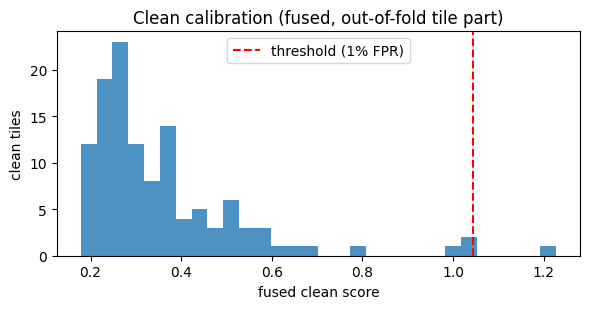

In [8]:
from sklearn.covariance import LedoitWolf
from sklearn.model_selection import GroupKFold

def trust_from_score(score, threshold):
    return float(100.0 / (1.0 + (score / threshold) ** 4))

def mahalanobis(x, mu, sd, loc, precision):
    z = (x - mu) / sd - loc
    return float(np.sqrt(max(z @ precision @ z, 0.0)))

def fit_clean_distribution(X):
    mu, sd = X.mean(0), X.std(0) + 1e-9
    return mu, sd, LedoitWolf().fit((X - mu) / sd)

def score_rows(X, mu, sd, lw):
    return np.array([mahalanobis(x, mu, sd, lw.location_, lw.precision_) for x in X])

# ---- one pass over the clean calibration tiles (error maps come from the cache of section 5)
calib_feats, calib_rel = [], []
t0 = time.time()
for p in tqdm(paths["calib"]):
    refl = to_reflectance(read_tile(p))
    maps = calib_maps[p]
    calib_feats.append(tile_features(refl, maps, err_scale, p99_ref))
    grid = patch_grid_features(refl, maps, err_scale)
    calib_rel.append(relative_patch_features(grid).reshape(-1, grid.shape[-1]))
calib_maps.clear()                                   # free ~250 MB
print(f"calib features in {time.time()-t0:.0f}s")

feature_names = list(calib_feats[0].keys())
X = np.array([[f[k] for k in feature_names] for f in calib_feats])
print("calib feature matrix:", X.shape)
if X.shape[0] < 3 * X.shape[1]:
    print(f"WARNING: {X.shape[0]} calib tiles for {X.shape[1]} features; the threshold will be noisy. Use more calib scenes.")

# ---- tile-level distribution: out-of-fold scores
calib_groups = df.loc[df["split"] == "calib", "scene_key"].values      # same order as paths["calib"]
n_splits = max(2, min(5, len(set(calib_groups))))
calib_scores = np.zeros(len(X))
for tr_idx, te_idx in GroupKFold(n_splits).split(X, groups=calib_groups):
    m_, s_, l_ = fit_clean_distribution(X[tr_idx])
    calib_scores[te_idx] = score_rows(X[te_idx], m_, s_, l_)
tile_thr = float(np.percentile(calib_scores, 99))
mu, sd, lw = fit_clean_distribution(X)
print(f"in-sample median {np.median(score_rows(X, mu, sd, lw)):.1f} vs out-of-fold median {np.median(calib_scores):.1f}")

# ---- patch-level distribution on RELATIVE patch features (patch vs the rest of its own tile)
P = np.vstack(calib_rel)
p_mu, p_sd = P.mean(0), P.std(0) + 1e-9
p_lw = LedoitWolf().fit((P - p_mu) / p_sd)

def patch_scores(rel_flat):
    z = (rel_flat - p_mu) / p_sd - p_lw.location_
    return np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", z, p_lw.precision_, z), 0))

calib_patch = [patch_scores(r_) for r_ in calib_rel]
calib_pmax = np.array([s.max() for s in calib_patch])
patch_thr = float(np.percentile(calib_pmax, 99))
heat_thr = float(np.percentile(np.concatenate(calib_patch), 99))

# ---- fused score and threshold (1 % FPR on clean calib)
fused = np.maximum(calib_scores / tile_thr, calib_pmax / patch_thr)
threshold = float(np.percentile(fused, 100 * (1 - FPR_TARGET)))

model = dict(regressors=regressors, err_scale=err_scale, p99_ref=p99_ref,
             feature_names=feature_names, mu=mu, sd=sd, loc=lw.location_, precision=lw.precision_,
             tile_thr=tile_thr, patch_thr=patch_thr, threshold=threshold,
             p_mu=p_mu, p_sd=p_sd, p_loc=p_lw.location_, p_precision=p_lw.precision_,
             heat_thr=heat_thr, expected_dtype=EXPECTED_DTYPE)
print(f"tile_thr {tile_thr:.2f} | patch_thr {patch_thr:.2f} | fused threshold {threshold:.2f} | heat_thr {heat_thr:.2f}")

print("median out-of-fold tile score per calib scene (a scene far above the rest inflates the threshold):")
print(pd.Series(calib_scores, index=calib_groups).groupby(level=0).median().round(1).sort_values().to_string())

plt.figure(figsize=(6, 3.2))
plt.hist(fused, bins=30, color="tab:blue", alpha=.8)
plt.axvline(threshold, color="red", ls="--", label="threshold (1% FPR)")
plt.xlabel("fused clean score"); plt.ylabel("clean tiles"); plt.legend(); plt.title("Clean calibration (fused, out-of-fold tile part)")
plt.tight_layout(); plt.show()

## 9. `authenticity(x)`: the detector

One function, one record per tile: `score`, `trust_score`, `channel_flags`, `heatmap` (+ the patch anomaly map and the feature vector `x`, used by the diagnostics).

`channel_flags` = the sanity-check flags + one flag per target band whose fraction of "too inconsistent" pixels is more than 5x what clean data gives (clean is about 1 %).

In [9]:
BAND_FLAG_FRAC = 0.05

def authenticity(arr, model):
    flags = sanity_checks(arr, model["expected_dtype"])
    if flags["band_count_bad"] or flags["shape_bad"]:       # cannot be analysed at all
        return dict(score=float("inf"), trust_score=0.0, channel_flags=flags,
                    heatmap=np.zeros((256, 256), np.float32), patch_anomaly=np.zeros((7, 7), np.float32), x=None)
    refl = to_reflectance(arr)
    maps = error_maps(refl, model["regressors"])
    feats = tile_features(refl, maps, model["err_scale"], model["p99_ref"])
    x = np.array([feats[k] for k in model["feature_names"]])
    tile_score = mahalanobis(x, model["mu"], model["sd"], model["loc"], model["precision"])

    grid = patch_grid_features(refl, maps, model["err_scale"])
    rel = relative_patch_features(grid).reshape(-1, grid.shape[-1])
    z = (rel - model["p_mu"]) / model["p_sd"] - model["p_loc"]
    pa = np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", z, model["p_precision"], z), 0)).reshape(grid.shape[:2])

    score = max(tile_score / model["tile_thr"], float(pa.max()) / model["patch_thr"])
    for b in TARGET_BANDS:
        flags[f"band_{b}_inconsistent"] = bool(feats[f"A_{b}_frac_over"] > BAND_FLAG_FRAC)
    return dict(score=float(score), tile_score=tile_score,
                trust_score=trust_from_score(score, model["threshold"]),
                channel_flags=flags, heatmap=patch_to_pixels(pa), patch_anomaly=pa.astype(np.float32), x=x)

# ---- honest false-positive rate on held-out TEST scenes
t0 = time.time()
test_results = [authenticity(read_tile(p), model) for p in tqdm(paths["test"])]
test_scores = np.array([r["score"] for r in test_results])
fpr_test = float((test_scores > model["threshold"]).mean())
lat = (time.time() - t0) / len(paths["test"])
print(f"measured false-positive rate on {len(paths['test'])} test tiles from held-out scenes: {fpr_test:.1%} (target {FPR_TARGET:.0%})")
print(f"latency: {lat*1000:.0f} ms / tile | mean trust on clean test: {np.mean([r['trust_score'] for r in test_results]):.1f}")

  0%|          | 0/126 [00:00<?, ?it/s]

measured false-positive rate on 126 test tiles from held-out scenes: 1.6% (target 1%)
latency: 1354 ms / tile | mean trust on clean test: 96.8


### Stage 4: provenance channel (not machine learning)
The georeference attack changes **0 pixels**, so no pixel model can see it. We use a signature instead:
`Ed25519( SHA-256(pixels + transform + CRS) )`, created by the data producer and verified by the defender.
The detector only reports `signature_ok` and `metadata_differs`. The demo below signs a clean tile, then shifts its geotransform by one pixel.

In [10]:
def metadata_string(transform, crs):
    return f"{tuple(transform)}|{crs}"

def provenance_digest(arr, transform, crs):
    h = hashlib.sha256()
    h.update(arr.tobytes()); h.update(metadata_string(transform, crs).encode())
    return h.digest()

def sign_tile(arr, transform, crs, private_key):
    return dict(signature=private_key.sign(provenance_digest(arr, transform, crs)),
                signed_meta=metadata_string(transform, crs))

def check_provenance(arr, transform, crs, record, public_key):
    from cryptography.exceptions import InvalidSignature
    try:
        public_key.verify(record["signature"], provenance_digest(arr, transform, crs))
        ok = True
    except InvalidSignature:
        ok = False
    return dict(signature_ok=ok, metadata_differs=metadata_string(transform, crs) != record["signed_meta"])

try:
    from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
    sk = Ed25519PrivateKey.generate(); pk = sk.public_key()
    with rasterio.open(paths["test"][0]) as src:
        a, tr, crs = src.read(), src.transform, src.crs
    rec = sign_tile(a, tr, crs, sk)
    print("untouched      :", check_provenance(a, tr, crs, rec, pk))
    shifted = rasterio.Affine(tr.a, tr.b, tr.c + 10 * tr.a, tr.d, tr.e, tr.f)   # georeference attack: 0 pixels change
    print("shifted georef :", check_provenance(a, shifted, crs, rec, pk))
except ImportError:
    print("`cryptography` not installed: run `pip install cryptography` to try the provenance demo")

untouched      : {'signature_ok': True, 'metadata_differs': False}
shifted georef : {'signature_ok': False, 'metadata_differs': True}


## 10. Attacks: only the teammates' real pairs are used (no self-made attacks)

Metrics per pair: score vs its own original, detection at the 1 %-FPR threshold, pixel IoU between `heatmap > heat_thr` and the true mask, and a **threshold-free pixel AUC** of the heatmap against the mask (0.5 = random).

In [11]:
from sklearn.metrics import roc_auc_score

def iou(pred, truth):
    union = (pred | truth).sum()
    return float((pred & truth).sum() / union) if union else 0.0

def pixel_auc(heat, mask):
    if mask.all() or not mask.any():
        return np.nan
    return float(roc_auc_score(mask.ravel(), heat.ravel()))

## 11. Teammates' pairs: scoring

Pairs are matched by file name (`pair_xxx_original / attacked / masks / manifest`). The mask comes from `pair_xxx_masks.npz`, the family from the manifest. A pair with 0 changed pixels and different metadata is flagged `metadata_only`: only the signature channel of Stage 4 can catch it. The signature is **not** counted for pixel attacks, because any pixel change breaks a hash by construction.

In [12]:
def load_gt_mask(npz_path, original, attacked):
    if isinstance(npz_path, str):
        z = np.load(npz_path)
        keys = [k for k in z.files if "mask" in k.lower()] or z.files
        m = np.zeros((256, 256), bool)
        for k in keys:
            a = np.squeeze(z[k])
            if a.shape == (256, 256):
                m |= a.astype(bool)
        if m.any():
            return m
    return (original != attacked).any(axis=0)

def read_meta(path):
    with rasterio.open(path) as s:
        return tuple(s.transform), str(s.crs)

def ndvi_mean(arr):
    r = to_reflectance(arr)
    return float(norm_diff(r[B["B8"]], r[B["B4"]]).mean())

pairs = find_pairs(PAIRS_DIR)
pair_cache, rows = {}, []
for _, r in tqdm(list(pairs.iterrows())):
    if not isinstance(r["attacked"], str):
        continue
    o, a = read_tile(r["original"]), read_tile(r["attacked"])
    mask = load_gt_mask(r["gt"], o, a)
    meta_diff = read_meta(r["original"]) != read_meta(r["attacked"])
    ro, ra = authenticity(o, model), authenticity(a, model)
    pair_cache[r["pair_id"]] = dict(ro=ro, ra=ra, mask=mask)
    rows.append(dict(pair=r["pair_id"], family=r["family"], changed_px=int(mask.sum()),
                     size_frac=float(mask.mean()), meta_diff=meta_diff,
                     metadata_only=bool(mask.sum() == 0 and meta_diff),
                     score_orig=ro["score"], score_att=ra["score"], trust_att=ra["trust_score"],
                     detected=ra["score"] > model["threshold"],
                     iou=iou(ra["heatmap"] > model["heat_thr"], mask) if mask.sum() else np.nan,
                     pixel_auc=pixel_auc(ra["heatmap"], mask),
                     ndvi_orig=ndvi_mean(o), ndvi_att=ndvi_mean(a)))
pair_results = pd.DataFrame(rows)
pair_results["delta"] = pair_results.score_att - pair_results.score_orig

# signature channel: only meaningful for metadata-only pairs
if "sk" in globals():
    sig = []
    for _, r in pairs.iterrows():
        if not isinstance(r["attacked"], str):
            continue
        with rasterio.open(r["original"]) as s0, rasterio.open(r["attacked"]) as s1:
            rec = sign_tile(s0.read(), s0.transform, s0.crs, sk)
            sig.append(not check_provenance(s1.read(), s1.transform, s1.crs, rec, pk)["signature_ok"])
    pair_results["signature_flag"] = sig
else:
    pair_results["signature_flag"] = False
pair_results["caught"] = pair_results.detected | (pair_results.metadata_only & pair_results.signature_flag)

pix = pair_results[~pair_results.metadata_only]
y = np.r_[np.zeros(len(pix)), np.ones(len(pix))]
auc_pairs = float(roc_auc_score(y, np.r_[pix.score_orig, pix.score_att]))
tpr_pairs = float(pix.detected.mean())
print("pairs:", len(pair_results), "| metadata-only (georef):", int(pair_results.metadata_only.sum()))
print(f"pixel pairs  AUC: {auc_pairs:.3f} | TPR@1%FPR: {tpr_pairs:.3f}")
print(f"attacked scores higher than its own original in {(pix.delta > 0).sum()}/{len(pix)} pairs | median delta {pix.delta.median():.3f}")
print("metadata-only pairs caught by signature:", int((pair_results.metadata_only & pair_results.signature_flag).sum()))
print(pair_results.groupby("family").agg(n=("pair", "size"), detected=("detected", "mean"), iou=("iou", "mean"),
      pixel_auc=("pixel_auc", "mean"), median_size=("size_frac", "median")).round(3))
display(pair_results.round(3))

  0%|          | 0/18 [00:00<?, ?it/s]

pairs: 18 | metadata-only (georef): 0
pixel pairs  AUC: 0.519 | TPR@1%FPR: 0.000
attacked scores higher than its own original in 10/18 pairs | median delta 0.002
metadata-only pairs caught by signature: 0
             n  detected    iou  pixel_auc  median_size
family                                                 
atmospheric  6       0.0  0.007      0.681        0.378
geometry     2       0.0  0.000      0.876        0.038
radiometry   2       0.0  0.000        NaN        1.000
sensor       2       0.0  0.000      0.294        0.040
spatial      6       0.0  0.000      0.513        0.037


,pair,family,changed_px,size_frac,meta_diff,metadata_only,score_orig,score_att,trust_att,detected,iou,pixel_auc,ndvi_orig,ndvi_att,delta,signature_flag,caught
0,pair_000001,spatial,2444,0.037,False,False,0.310,0.233,99.753,False,0.000,0.702,0.457,0.453,-0.077,True,False
1,pair_000002,spatial,2698,0.041,False,False,0.300,0.303,99.298,False,0.000,0.534,0.409,0.411,0.003,True,False
2,pair_000003,atmospheric,65536,1.000,False,False,0.281,0.297,99.351,False,0.000,NaN,0.502,0.465,0.016,True,False
3,pair_000004,atmospheric,20972,0.320,False,False,0.204,0.413,97.616,False,0.000,0.753,0.531,0.522,0.209,True,False
4,pair_000005,atmospheric,25017,0.382,False,False,0.249,0.403,97.841,False,0.000,0.749,0.555,0.541,0.154,True,False
5,pair_000006,geometry,2389,0.036,False,False,0.250,0.265,99.589,False,0.000,0.867,0.574,0.574,0.015,True,False
6,pair_000007,radiometry,65536,1.000,False,False,0.263,0.235,99.746,False,0.000,NaN,0.552,0.613,-0.028,True,False
7,pair_000009,sensor,2754,0.042,False,False,0.320,0.324,99.089,False,0.000,0.216,0.516,0.516,0.003,True,False
8,pair_000010,spatial,2697,0.041,False,False,0.249,0.247,99.689,False,0.000,0.349,0.534,0.536,-0.002,True,False
9,pair_000011,spatial,2397,0.037,False,False,0.239,0.205,99.851,False,0.000,0.370,0.524,0.523,-0.033,True,False


### 11b. Diagnostic: can any tile feature see these attacks?

For every real pair we measure how much each of the 87 tile features moves because of the attack, in units of the **normal scene-to-scene std** of that feature (`|z|`).
* `max |z|` above about 2: some feature reacts, a score built on it can work.
* `max |z|` below about 1 for every feature: the edit is smaller than natural variation, and **no tile-level detector without a reference can separate it**. That is a finding for the report.

This uses the originals, so it is for diagnosis only, not part of the detector.

In [13]:
zs, fams = [], []
for _, r in pair_results[~pair_results.metadata_only].iterrows():
    c = pair_cache[r["pair"]]
    if c["ro"]["x"] is None or c["ra"]["x"] is None:
        continue
    zs.append((c["ra"]["x"] - c["ro"]["x"]) / model["sd"]); fams.append(r["family"])
Z = pd.DataFrame(zs, columns=feature_names); Z["family"] = fams
feature_response = Z.groupby("family")[feature_names].apply(lambda d: d.abs().mean())
for fam, row in feature_response.iterrows():
    print(f"{fam:12s} max |z| = {row.max():8.2f} | top features:", row.sort_values(ascending=False).head(4).round(2).to_dict())

atmospheric  max |z| =     1.32 | top features: {'B_ratio_B1_B2': 1.32, 'B_B9_log_resid_std': 0.74, 'B_B8A_log_resid_std': 0.66, 'B_ratio_B8_B8A': 0.65}
geometry     max |z| =     0.04 | top features: {'A_B8_p99': 0.04, 'B_ratio_B8_B8A': 0.03, 'B_ratio_B7_B8': 0.02, 'A_B8_p95': 0.01}
radiometry   max |z| =     1.23 | top features: {'B_ratio_B4_B5': 1.23, 'B_ratio_B3_B4': 1.03, 'C_NDVI_p5': 0.44, 'C_edge_mismatch_B4_B8': 0.4}
sensor       max |z| =     0.25 | top features: {'B_ratio_B1_B2': 0.25, 'B_B9_localvar_cv': 0.17, 'B_B7_resid_kurtosis': 0.14, 'B_B8_resid_kurtosis': 0.12}
spatial      max |z| =     0.06 | top features: {'B_ratio_B8_B8A': 0.06, 'B_B8_localvar_cv': 0.05, 'C_NBR_p95': 0.05, 'B_B8A_localvar_cv': 0.05}


## 12. By-size and leave-one-attack-family-out evaluation

**Detection by size.** In the 2018 forgery paper (Yarlagadda et al.), AUC went 0.80 / 0.92 / 0.97 for small / medium / large forgeries (RGB Landsat, copy-paste only: it supports the design, it is *not* our expected accuracy). We check whether the same trend appears here.

**Leave-one-attack-family-out (LOFO).** The core model never sees attacks, so its numbers are already "unseen attack" numbers. The optional supervised upgrade is where leakage can happen, so here we fuse `[log(score/threshold), max heatmap, max patch anomaly]` with a logistic regression trained on calib tiles with **all families except one**, and test on the held-out family. That is the honest unseen-attack number for a supervised layer.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

rows = []
for _, r in pair_results[~pair_results.metadata_only].iterrows():
    c = pair_cache[r["pair"]]
    for yy, res in [(0, c["ro"]), (1, c["ra"])]:
        rows.append(dict(pair=r["pair"], family=r["family"], y=yy, score=res["score"],
                         hmax=float(res["heatmap"].max()), pmax=float(res["patch_anomaly"].max()),
                         size_frac=r["size_frac"], iou=r["iou"] if yy else np.nan))
pf = pd.DataFrame(rows)

# 1. per-family, core (clean-only) detector, using that family's own originals
fam_rows = []
for fam, g in pf.groupby("family"):
    if g.y.nunique() < 2:
        continue
    a = g[g.y == 1]
    fam_rows.append(dict(family=fam, n=len(a), AUC=roc_auc_score(g.y, g.score),
                         TPR_at_1pct_FPR=(a.score > model["threshold"]).mean(),
                         IoU=a.iou.mean(), median_size=a.size_frac.median()))
fam_table = pd.DataFrame(fam_rows).round(3)
display(fam_table)

# 2. by true attack size (the real pairs are ~4 %, ~32-38 % and 100 % of the tile)
att = pf[pf.y == 1].copy()
att["size_bin"] = pd.cut(att.size_frac, [0, 0.10, 0.50, 1.0], labels=["local <10%", "medium 10-50%", "full tile"], include_lowest=True)
clean = pf[pf.y == 0].score.values
for b, g in att.groupby("size_bin", observed=True):
    yy = np.r_[np.zeros(len(clean)), np.ones(len(g))]
    print(f"{b:14s} n={len(g):2d}  AUC={roc_auc_score(yy, np.r_[clean, g.score.values]):.3f}")

# 3. leave-one-family-out with a logistic fusion
def fusion_X(d):
    return np.c_[np.log(np.maximum(d.score.values, 1e-6) / model["threshold"]), d.hmax.values, d.pmax.values]

fams = pf.family.unique()
print("families:", list(fams))
lofo_rows = []
if len(fams) < 2:
    print("Only one family found: LOFO skipped. Fix FAMILY_KEYS in section 3.")
else:
    for held in fams:
        tr, te = pf[pf.family != held], pf[pf.family == held]
        if tr.y.nunique() < 2 or te.y.nunique() < 2:
            continue
        sc = StandardScaler().fit(fusion_X(tr))
        clf = LogisticRegression(class_weight="balanced", max_iter=1000).fit(sc.transform(fusion_X(tr)), tr.y)
        p = clf.predict_proba(sc.transform(fusion_X(te)))[:, 1]
        lofo_rows.append(dict(held_out_family=held, n_pairs=int(te.y.sum()),
                              AUC_core=roc_auc_score(te.y, te.score), AUC_fused_unseen=roc_auc_score(te.y, p)))
lofo = pd.DataFrame(lofo_rows).round(3)
display(lofo)

,family,n,AUC,TPR_at_1pct_FPR,IoU,median_size
0,atmospheric,6,0.750,0.0,0.007,0.378
1,geometry,2,0.500,0.0,0.000,0.038
2,radiometry,2,0.500,0.0,0.000,1.000
3,sensor,2,0.750,0.0,0.000,0.040
4,spatial,6,0.306,0.0,0.000,0.037


local <10%     n=10  AUC=0.461
medium 10-50%  n= 4  AUC=0.875
full tile      n= 4  AUC=0.306
families: ['spatial', 'atmospheric', 'geometry', 'radiometry', 'sensor']


,held_out_family,n_pairs,AUC_core,AUC_fused_unseen
0,spatial,6,0.306,0.306
1,atmospheric,6,0.750,0.250
2,geometry,2,0.500,0.500
3,radiometry,2,0.500,0.500
4,sensor,2,0.750,0.750


## 13. Decision impact on the real attacks

The defender uses an NDVI-based decision. We compute mean NDVI before and after each real attack and count how often a simple rule (`mean NDVI > 0.3` = "vegetated") flips. The 0.3 value is a placeholder: use the defender's real rule. `harmful_and_missed` = decision flips that the detector did not flag (the signature only counts for metadata-only pairs).

In [15]:
NDVI_T = 0.3   # placeholder: use the defender's real rule
pair_results["ndvi_shift"] = pair_results.ndvi_att - pair_results.ndvi_orig
pair_results["decision_flip"] = (pair_results.ndvi_orig > NDVI_T) != (pair_results.ndvi_att > NDVI_T)
pair_results["evaded_and_flips"] = pair_results.decision_flip & ~pair_results.caught

decision = pair_results.groupby("family").agg(
    n=("pair","size"), mean_abs_ndvi_shift=("ndvi_shift", lambda s: s.abs().mean()),
    flip_rate=("decision_flip","mean"), detected=("detected","mean"),
    caught_incl_signature=("caught","mean"), harmful_and_missed=("evaded_and_flips","sum")).round(3)
display(decision)
print("Attacks that change the defender's decision AND were not caught:",
      pair_results[pair_results.evaded_and_flips].pair.tolist())

,n,mean_abs_ndvi_shift,flip_rate,detected,caught_incl_signature,harmful_and_missed
family,,,,,,
atmospheric,6,0.017,0.0,0.0,0.0,0
geometry,2,0.000,0.0,0.0,0.0,0
radiometry,2,0.065,0.0,0.0,0.0,0
sensor,2,0.000,0.0,0.0,0.0,0
spatial,6,0.002,0.0,0.0,0.0,0


Attacks that change the defender's decision AND were not caught: []


## 14. Export: JSON record per tile, model arrays, plots, cost numbers

The defender only consumes the record `trust_score`, `channel_flags`, `heatmap`. We write `records.json` (clean test tiles + the teammates' attacked tiles, with a coarse 7x7 heatmap), `heatmaps.npz`, `detector_arrays.npz` + `regressors.pkl` (everything needed to rebuild `authenticity`), result CSVs, two figures and a cost table.

,latency_ms_median,latency_ms_p95,model_size_MB,process_memory_MB
0,1318.7,1458.1,1.5,559.7


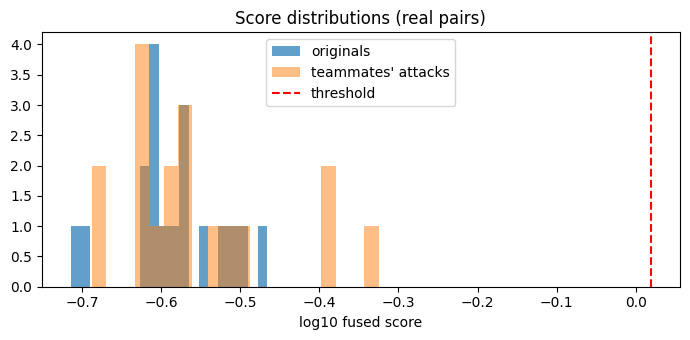

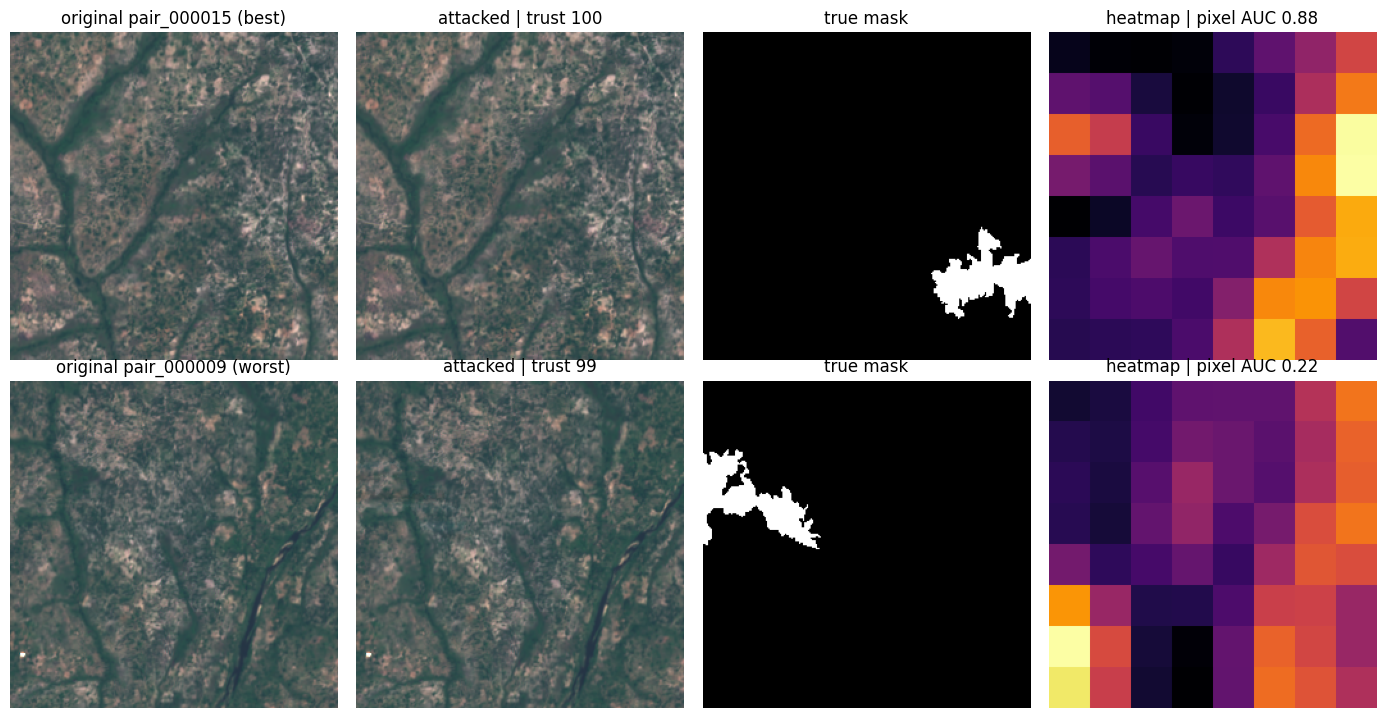

{'test_FPR': 0.015873015873015872, 'threshold': 1.0448794975432971, 'pairs_AUC': 0.5185185185185186, 'pairs_TPR_at_1pct_FPR': 0.0, 'n_pairs': 18, 'n_metadata_only': 0, 'median_latency_ms': 1318.739420500151}
saved: ['cost.csv', 'decision_impact.csv', 'detector_arrays.npz', 'feature_response_z.csv', 'fig_example.png', 'fig_scores.png', 'heatmaps.npz', 'lofo_results.csv', 'pair_results.csv', 'per_family_results.csv', 'records.json', 'regressors.pkl', 'summary.json']


In [16]:
def to_record(path, res):
    grid7 = res["heatmap"][::36, ::36][:7, :7]
    return dict(tile=os.path.basename(path), trust_score=round(res["trust_score"], 2),
                score=None if np.isinf(res["score"]) else round(res["score"], 3),
                channel_flags={k: bool(v) for k, v in res["channel_flags"].items()},
                heatmap_coarse_7x7=np.round(grid7, 2).tolist())

records = [to_record(p, r_) for p, r_ in zip(paths["test"], test_results)]
for _, p in pairs.iterrows():
    if p["pair_id"] in pair_cache:
        records.append(to_record(p["attacked"], pair_cache[p["pair_id"]]["ra"]))
with open(f"{OUT_DIR}/records.json", "w") as f:
    json.dump(records, f, indent=1)

hm = {os.path.basename(p): r_["heatmap"].astype(np.float16) for p, r_ in zip(paths["test"][:50], test_results[:50])}
hm.update({f"{k}_attacked": v["ra"]["heatmap"].astype(np.float16) for k, v in pair_cache.items()})
np.savez_compressed(f"{OUT_DIR}/heatmaps.npz", **hm)

arrays = {k: model[k] for k in ["mu","sd","loc","precision","p_mu","p_sd","p_loc","p_precision"]}
extra = {k: model[k] for k in ["threshold","heat_thr","tile_thr","patch_thr"]}
np.savez(f"{OUT_DIR}/detector_arrays.npz", **extra, **arrays)
with open(f"{OUT_DIR}/regressors.pkl", "wb") as f:
    pickle.dump(dict(regressors=model["regressors"], err_scale=model["err_scale"], p99_ref=model["p99_ref"],
                     feature_names=model["feature_names"], expected_dtype=model["expected_dtype"]), f)

# cost numbers
lat_ms = []
for p in paths["test"][:20]:
    arr = read_tile(p); t = time.perf_counter(); authenticity(arr, model); lat_ms.append((time.perf_counter() - t) * 1000)
size_mb = sum(os.path.getsize(f"{OUT_DIR}/{n}") for n in ["detector_arrays.npz", "regressors.pkl"]) / 1e6
try:
    import psutil; rss_mb = psutil.Process().memory_info().rss / 1e6
except ImportError:
    rss_mb = float("nan")
cost = pd.DataFrame([dict(latency_ms_median=np.median(lat_ms), latency_ms_p95=np.percentile(lat_ms, 95),
                          model_size_MB=size_mb, process_memory_MB=rss_mb)]).round(1)
display(cost)

cost.to_csv(f"{OUT_DIR}/cost.csv", index=False)
pair_results.to_csv(f"{OUT_DIR}/pair_results.csv", index=False)
fam_table.to_csv(f"{OUT_DIR}/per_family_results.csv", index=False)
lofo.to_csv(f"{OUT_DIR}/lofo_results.csv", index=False)
decision.to_csv(f"{OUT_DIR}/decision_impact.csv")
feature_response.to_csv(f"{OUT_DIR}/feature_response_z.csv")

# figure 1: originals vs teammates' attacked scores
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(pf[pf.y == 0].score), bins=20, alpha=.7, label="originals")
ax.hist(np.log10(pf[pf.y == 1].score), bins=20, alpha=.5, label="teammates' attacks")
ax.axvline(np.log10(model["threshold"]), color="red", ls="--", label="threshold")
ax.set_xlabel("log10 fused score"); ax.legend(); ax.set_title("Score distributions (real pairs)")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_scores.png", dpi=150); plt.show()

# figure 2: best and worst localised local attack (shown honestly, not only the best)
rgb = lambda x: np.clip(np.transpose(x[[B["B4"], B["B3"], B["B2"]]], (1, 2, 0)) / 0.3, 0, 1)
cand = pair_results[(pair_results.size_frac > 0) & (pair_results.size_frac < 0.5)].dropna(subset=["pixel_auc"]).sort_values("pixel_auc")
ids = [cand.iloc[-1].pair, cand.iloc[0].pair] if len(cand) >= 2 else pair_results.pair.tolist()[:1]
fig, axs = plt.subplots(len(ids), 4, figsize=(14, 3.6 * len(ids)), squeeze=False)
for k, pid in enumerate(ids):
    row = pairs[pairs.pair_id == pid].iloc[0]; c = pair_cache[pid]
    o, a = read_tile(row["original"]), read_tile(row["attacked"])
    pa_ = pair_results.set_index("pair").loc[pid, "pixel_auc"]
    axs[k, 0].imshow(rgb(to_reflectance(o))); axs[k, 0].set_title(f"original {pid}" + (" (best)" if k == 0 and len(ids) > 1 else " (worst)" if k == 1 else ""))
    axs[k, 1].imshow(rgb(to_reflectance(a))); axs[k, 1].set_title(f"attacked | trust {c['ra']['trust_score']:.0f}")
    axs[k, 2].imshow(c["mask"], cmap="gray"); axs[k, 2].set_title("true mask")
    axs[k, 3].imshow(c["ra"]["heatmap"], cmap="inferno"); axs[k, 3].set_title(f"heatmap | pixel AUC {pa_:.2f}")
    for ax_ in axs[k]: ax_.axis("off")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_example.png", dpi=150); plt.show()

# headline numbers for the report
summary = dict(test_FPR=fpr_test, threshold=threshold, pairs_AUC=auc_pairs, pairs_TPR_at_1pct_FPR=tpr_pairs,
               n_pairs=len(pair_results), n_metadata_only=int(pair_results.metadata_only.sum()),
               median_latency_ms=float(np.median(lat_ms)))
json.dump(summary, open(f"{OUT_DIR}/summary.json", "w"), indent=1)
print(summary)
print("saved:", sorted(os.listdir(OUT_DIR)))

## Known limits (say them openly in the report)
* The 1 % false-positive rate holds on regions like the clean set: use the **measured** test-scene rate (section 9).
* Real-pair results rest on only 18 pairs (2 to 6 per family): per-family numbers are indicative only, and the pairs must not be used to tune the threshold.
* The diagnostic in 11b shows how far each real attack moves the features compared with natural scene-to-scene variation. Attacks that move nothing cannot be detected by a clean-only, reference-free model.
* The georeference attack is invisible to pixels: it relies on the signature channel (needs the producer to sign tiles).
* The cloud-pattern rule and the NDVI decision rule are placeholders until the defender's rule is known.
* Features are fitted on one spring ROI set only. If the real test data comes from other seasons, add tiles from those archives.